In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target)

print("Wine Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Target Classes:", wine.target_names)

Wine Dataset Loaded Successfully!
Dataset Shape: (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']


In [3]:
print("First 5 Rows:")
print(X.head())

First 5 Rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0    

In [4]:
print("Feature Names:")
print(X.columns.tolist())

Feature Names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [5]:
print("Target Classes:")
print(wine.target_names)

print("\nClass Distribution:")
print(y.value_counts().sort_index())

Target Classes:
['class_0' 'class_1' 'class_2']

Class Distribution:
0    59
1    71
2    48
Name: count, dtype: int64


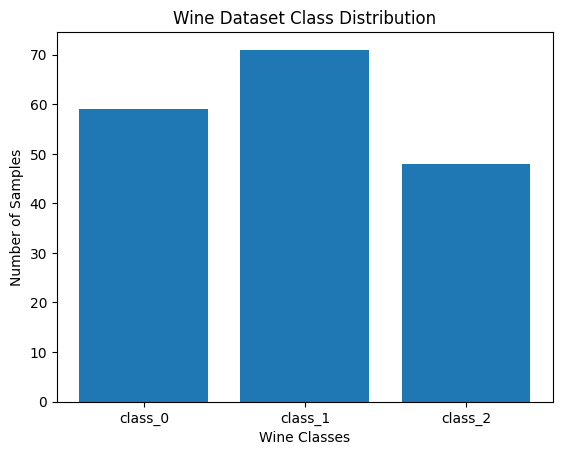

In [6]:
class_counts = y.value_counts().sort_index()

plt.bar(wine.target_names, class_counts)

plt.title("Wine Dataset Class Distribution")
plt.xlabel("Wine Classes")
plt.ylabel("Number of Samples")

plt.savefig("class_distribution.png")
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 142
Testing Samples: 36


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [10]:
model = LogisticRegression(max_iter=5000)

model.fit(X_train_scaled, y_train)

print("Model Training Completed!")

Model Training Completed!


In [11]:
y_pred = model.predict(X_test_scaled)

print("Actual Classes:")
print(y_test.head(10).values)

print("\nPredicted Classes:")
print(y_pred[:10])

Actual Classes:
[0 2 0 1 1 0 0 1 1 2]

Predicted Classes:
[0 1 0 1 1 0 0 1 1 2]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.9722222222222222
Accuracy Percentage: 97.22222222222221 %


In [13]:
precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Precision:", precision)

Precision: 0.974074074074074


In [14]:
recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Recall:", recall)

Recall: 0.9722222222222222


In [15]:
f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("F1-Score:", f1)

F1-Score: 0.9719701552732407


In [16]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

print(results)

      Metric     Score
0   Accuracy  0.972222
1  Precision  0.974074
2     Recall  0.972222
3   F1-Score  0.971970


In [17]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]


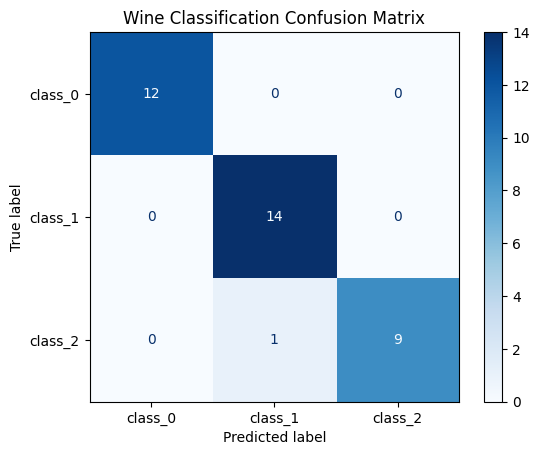

In [18]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

display.plot(cmap="Blues")

plt.title("Wine Classification Confusion Matrix")

plt.savefig("confusion_matrix_wine.png")
plt.show()

In [19]:
report = classification_report(
    y_test,
    y_pred,
    target_names=wine.target_names
)

print(report)

with open("classification_report.txt", "w") as file:
    file.write(report)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

